# Proyecto final — Procesamiento Digital de Señales
## Limpieza de voz: diseño FIR por ventanas, plano Z y contraste con IIR

Alumnas:
- Jaramillo Rodriguez Leslie Citlalli
- Lopez MOntero Ivana Abigail
- Salas Hernandez Camila Alexandra

## 0. Preparación y carga de audios

In [ ]:
import os, glob, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9})
os.makedirs('salidas/extra', exist_ok=True); os.makedirs('figuras', exist_ok=True)

def buscar_wav(patron):
    c = [p for p in sorted(glob.glob(f'**/*{patron}*.wav', recursive=True)) if not p.startswith('salidas')]
    return c[0] if c else None

ARCH_A, ARCH_B = buscar_wav('voz_60Hz'), buscar_wav('fuente_simulada')
if ARCH_A is None or ARCH_B is None:
    try:
        from google.colab import files
        print('Sube PDS_voz_60Hz_4s.wav y PDS_voz_fuente_simulada_4s.wav'); files.upload()
        ARCH_A, ARCH_B = buscar_wav('voz_60Hz'), buscar_wav('fuente_simulada')
    except ImportError:
        pass
assert ARCH_A and ARCH_B, 'No encontré los WAV: colócalos junto al notebook.'

def leer(arch):
    fs, x = wavfile.read(arch)
    if np.issubdtype(x.dtype, np.integer):
        x = x / float(np.iinfo(x.dtype).max + 1)
    if x.ndim > 1: x = x.mean(axis=1)
    return fs, x.astype(float)

fsA, xA = leer(ARCH_A); fsB, xB = leer(ARCH_B)
assert fsA == fsB
fs = fsA; Nx = len(xA); t = np.arange(Nx) / fs
print(f'A: {ARCH_A}  fs = {fsA} Hz, {len(xA)} muestras = {len(xA)/fsA:.2f} s, pico = {np.max(abs(xA)):.3f}')
print(f'B: {ARCH_B}  fs = {fsB} Hz, {len(xB)} muestras = {len(xB)/fsB:.2f} s, pico = {np.max(abs(xB)):.3f}')
print(f'Nyquist = {fs/2:.0f} Hz')

def guardar(nombre, y):
    y = np.asarray(y, float); pico = np.max(np.abs(y))
    if pico > 1: y = y / pico * 0.99; print(f'  (se reescaló {nombre}: pico {pico:.2f})')
    wavfile.write(os.path.join('salidas', nombre), fs, np.round(y * 32767).astype(np.int16))
    print(f'  guardado salidas/{nombre}')

def escuchar(y, titulo):
    print(titulo); display(Audio(y, rate=fs))

escuchar(xA, 'Audio A original (voz + 60 Hz)')
escuchar(xB, 'Audio B original (voz + fuente simulada)')

A: PDS_voz_60Hz_4s.wav  fs = 16000 Hz, 64000 muestras = 4.00 s, pico = 0.524
B: PDS_voz_fuente_simulada_4s.wav  fs = 16000 Hz, 64000 muestras = 4.00 s, pico = 0.616
Nyquist = 8000 Hz
Audio A original (voz + 60 Hz)


Audio B original (voz + fuente simulada)


## 1. Núcleo del plano Z (reutilizado del Proyecto Parcial 2)




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import signal
import textwrap

def fmt(c, d=3):
    c = complex(c)
    if abs(c.imag) < 1e-9:
        return f"{c.real:.{d}g}"
    return f"{c.real:.{d}g}{c.imag:+.{d}g}j"

class SistemaZ:
    def __init__(self, polos=None, ceros=None, K=1.0):
        self.polos = [complex(p) for p in (polos or [])]
        self.ceros = [complex(z) for z in (ceros or [])]
        self.K = float(K)

    # ---------- edición ----------
    def agregar(self, r, tipo):
        r = complex(r)
        lista = self.polos if tipo == 'polo' else self.ceros
        lista.append(r)
        if abs(r.imag) > 1e-9:
            lista.append(np.conj(r))

    def agregar_par(self, radio, ang, tipo):
        self.agregar(radio * np.exp(1j * ang), tipo)

    def limpiar(self):
        self.polos.clear(); self.ceros.clear()

    # ---------- función de transferencia ----------
    def _efectivo(self):
        # Si M > N se agregan (M-N) polos en z=0 para que el sistema sea causal
        extra = max(0, len(self.ceros) - len(self.polos))
        return list(self.ceros), list(self.polos) + [0j] * extra, extra

    def coef(self):
        # Coeficientes de H(z)=B(z)/A(z) en potencias DESCENDENTES de z
        z, p, _ = self._efectivo()
        num = self.K * np.atleast_1d(np.real(np.poly(z)))
        den = np.atleast_1d(np.real(np.poly(p)))
        return num, den

    def coef_zinv(self):
        # Forma en z^-1 (la que usa lfilter): b tiene N+1 términos (rellena con ceros a la izquierda)
        num, den = self.coef()
        b = np.concatenate([np.zeros(len(den) - len(num)), num])
        return b, den

    # ---------- respuesta en frecuencia ----------
    def H(self, w):
        w = np.asarray(w, dtype=float)
        ejw = np.exp(1j * w)
        z, p, _ = self._efectivo()
        num = self.K * np.ones_like(ejw, dtype=complex)
        for zi in z: num = num * (ejw - zi)
        den = np.ones_like(ejw, dtype=complex)
        for pk in p: den = den * (ejw - pk)
        with np.errstate(divide='ignore', invalid='ignore'):
            Hw = np.where(np.abs(den) < 1e-9, np.nan + 0j, num / den)   # polo sobre el círculo -> no definido
        return Hw

    # ---------- impulso ----------
    def impulso(self, N=60):
        b, a = self.coef_zinv()
        x = np.zeros(N); x[0] = 1.0
        return signal.lfilter(b, a, x)

    # ---------- estabilidad ----------
    def estabilidad(self):
        if not self.polos:
            return "ESTABLE (FIR: no hay polos)"
        rmax = max(abs(p) for p in self.polos)
        if rmax < 1 - 1e-9:  return f"ESTABLE (|p|máx = {rmax:.4f} < 1)"
        if rmax <= 1 + 1e-9: return f"MARGINALMENTE ESTABLE (hay polo en |z|=1; |H| no definida ahí)"
        return f"INESTABLE (|p|máx = {rmax:.4f} > 1)"

    # ---------- geometría ----------
    def geometria(self, w0):
        pt = np.exp(1j * w0)
        dz = [abs(pt - z) for z in self.ceros]
        dp = [abs(pt - p) for p in self.polos]
        return pt, dz, dp

    def normalizar(self, w_ref=None):
        # Ajusta K: |H(w_ref)| = 1; si w_ref es None, el máximo de |H| en [0, pi] será 1
        self.K = 1.0
        w = np.linspace(0, np.pi, 2048) if w_ref is None else np.array([w_ref])
        m = np.nanmax(np.abs(self.H(w))) if len(w) else 1
        if np.isfinite(m) and m > 1e-12:
            self.K = 1.0 / m
        return self.K

def banda_3dB(s):
    # Borde(s) de la banda donde |H| >= max/sqrt(2)
    w = np.linspace(0, np.pi, 8192)
    m = np.abs(s.H(w)); idx = np.where(m >= np.nanmax(m) / np.sqrt(2))[0]
    return w[idx[0]], w[idx[-1]]

In [ ]:
def dibujar_plano(ax, s, w0=None):
    ax.clear()
    t = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(t), np.sin(t), 'k-', lw=1)
    ax.axhline(0, color='gray', lw=.6); ax.axvline(0, color='gray', lw=.6)
    for lista, mk, col, lab in ((s.ceros, 'o', 'tab:blue', 'Ceros'), (s.polos, 'x', 'tab:red', 'Polos')):
        if lista:
            ax.plot([r.real for r in lista], [r.imag for r in lista], mk, color=col, ms=9,
                    mew=2, mfc='none', ls='', label=lab)
            # multiplicidad (raíces repetidas)
            vistos = {}
            for r in lista:
                k = (round(r.real, 5), round(r.imag, 5)); vistos[k] = vistos.get(k, 0) + 1
            for (x, y), n in vistos.items():
                if n > 1: ax.annotate(f"({n})", (x, y), textcoords='offset points', xytext=(7, 7), color=col)
    if w0 is not None:
        pt = np.exp(1j * w0)
        ax.plot(pt.real, pt.imag, 'o', color='tab:green', ms=8, label=r'$e^{j\omega}$')
        for r in s.ceros: ax.plot([pt.real, r.real], [pt.imag, r.imag], '--', color='tab:blue', lw=.7, alpha=.7)
        for r in s.polos: ax.plot([pt.real, r.real], [pt.imag, r.imag], '--', color='tab:red', lw=.7, alpha=.7)
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_aspect('equal')
    ax.set_xlabel('Re{z}'); ax.set_ylabel('Im{z}'); ax.set_title('Plano Z')
    ax.grid(alpha=.3)
    if s.ceros or s.polos or w0 is not None: ax.legend(loc='upper right', fontsize=8)

def dibujar_respuestas(axm, axp, axi, s, w0=None, db=False, N=60):
    w = np.linspace(0, np.pi, 1024)
    Hw = s.H(w); mag = np.abs(Hw); fin = np.isfinite(Hw)
    ph = np.full_like(w, np.nan); ph[fin] = np.unwrap(np.angle(Hw[fin]))
    axm.clear(); axp.clear(); axi.clear()
    if db:
        with np.errstate(divide='ignore'):
            y = 20*np.log10(np.maximum(mag, 1e-6))
        axm.plot(w, y); axm.set_ylabel('|H| (dB)')
    else:
        y = mag; axm.plot(w, y); axm.set_ylabel(r'$|H(e^{j\omega})|$')
    axm.set_title('Magnitud'); axm.set_xlim(0, np.pi); axm.grid(alpha=.3)
    axp.plot(w, ph, color='tab:orange'); axp.set_xlim(0, np.pi); axp.grid(alpha=.3)
    axp.set_title('Fase'); axp.set_ylabel('∠H (rad)'); axp.set_xlabel('ω (rad/muestra)')
    if w0 is not None and np.isfinite(s.H(w0)):
        h0 = s.H(w0)
        axm.plot([w0], [20*np.log10(max(abs(h0), 1e-6)) if db else abs(h0)], 'o', color='tab:green')
        axm.axvline(w0, color='tab:green', ls=':')
        axp.plot([w0], [np.interp(w0, w[fin], ph[fin])], 'o', color='tab:green'); axp.axvline(w0, color='tab:green', ls=':')
    if len(s.polos) and max(abs(p) for p in s.polos) > 1e-9 and any(abs(abs(p) - 1) < 1e-9 for p in s.polos):
        axm.text(.5, .9, 'polo en |z|=1: |H| no definida', transform=axm.transAxes, ha='center', color='red', fontsize=8)
    h = s.impulso(N); n = np.arange(N)
    axi.stem(n, h, basefmt=' '); axi.set_title(f'Respuesta al impulso h[n] ({N} muestras)')
    axi.set_xlabel('n'); axi.set_ylabel('h[n]'); axi.grid(alpha=.3)

def texto_sistema(s, w0=None):
    z, p, extra = s._efectivo()
    num, den = s.coef()
    L = []
    L.append("H(z) = K · Π(z − zᵢ) / Π(z − pₖ)")
    L.append(f"K = {s.K:.5g}")
    L.append("Ceros : " + (", ".join(fmt(c) for c in s.ceros) or "(ninguno)"))
    L.append("Polos : " + (", ".join(fmt(c) for c in s.polos) or "(ninguno)"))
    if extra: L.append(f"AVISO: más ceros que polos -> se agregaron {extra} polo(s) en z=0 (retardo) para tener un sistema causal.")
    nf = "".join(f"(z − ({fmt(c)}))" for c in z) or "1"
    df = "".join(f"(z − ({fmt(c)}))" for c in p) or "1"
    L.append("Forma factorizada:")
    L.append(textwrap.fill(f"H(z) = {s.K:.4g} · {nf} / [{df}]", 110, subsequent_indent="    "))
    L.append("Numerador B(z) (potencias descendentes de z): " + np.array2string(num, precision=4, suppress_small=True))
    L.append("Denominador A(z) (potencias descendentes de z): " + np.array2string(den, precision=4, suppress_small=True))
    L.append("Estabilidad (causal): " + s.estabilidad())
    if w0 is not None:
        pt, dz, dp = s.geometria(w0)
        Hv = s.H(w0)
        L.append(f"--- ω = {w0:.3f} rad  (e^jω = {fmt(pt)}) ---")
        L.append("Distancias a los ceros : " + (", ".join(f"{d:.3f}" for d in dz) or "-"))
        L.append("Distancias a los polos : " + (", ".join(f"{d:.3f}" for d in dp) or "-"))
        if np.isfinite(Hv):
            L.append(f"|H| = {abs(Hv):.4f}   ∠H = {np.angle(Hv):.4f} rad   (H = {fmt(Hv, 4)})")
            ch = abs(s.K) * np.prod(dz) / np.prod(dp) if len(dp) else abs(s.K) * np.prod(dz)
            if extra == 0: L.append(f"Verificación K·Πd_z/Πd_p = {ch:.4f}")
        else:
            L.append("|H| NO DEFINIDA (polo sobre el círculo unitario)")
    return "\n".join(L)

def mostrar(s, titulo="", w0=None, db=False, N=60):
    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(2, 3, figure=fig, width_ratios=[1.1, 1, 1])
    axz = fig.add_subplot(gs[:, 0]); axm = fig.add_subplot(gs[0, 1]); axp = fig.add_subplot(gs[1, 1]); axi = fig.add_subplot(gs[:, 2])
    dibujar_plano(axz, s, w0); dibujar_respuestas(axm, axp, axi, s, w0, db, N)
    fig.suptitle(titulo, fontsize=13); fig.tight_layout(); plt.show()
    print(texto_sistema(s, w0))

### 1.3 Extensión para FIR: `SistemaFIR(SistemaZ)`



In [ ]:
class SistemaFIR(SistemaZ):
    """FIR: N-1 polos en z=0 y ceros = raíces de h[n]. Hereda la graficación del plano Z de SistemaZ."""
    def __init__(self, h, nombre='FIR'):
        self.h = np.asarray(h, float); self.nombre = nombre
        nz = np.flatnonzero(self.h)
        ceros = np.roots(self.h)                       # np.roots ignora coeficientes iniciales nulos
        super().__init__(polos=[0j] * (len(self.h) - 1), ceros=list(ceros), K=self.h[nz[0]])

    def coef(self):        # potencias descendentes de z
        return self.h.copy(), np.r_[1.0, np.zeros(len(self.h) - 1)]
    def coef_zinv(self):   # forma en z^-1 (lfilter)
        return self.h.copy(), np.array([1.0])
    def H(self, w):
        w = np.asarray(w, float)
        _, Hw = signal.freqz(self.h, 1, worN=np.atleast_1d(w))
        return Hw if w.ndim else Hw[0]
    def H_geometrica(self, w0):
        """|H| = |K|·Π d_ceros / Π d_polos (los polos están en 0 -> distancia 1); fase con ángulos."""
        e = np.exp(1j * w0); zc = np.array(self.ceros)
        logm = np.log(abs(self.K)) + np.sum(np.log(np.abs(e - zc)))
        fase = np.angle(self.K) + np.sum(np.angle(e - zc)) - len(self.polos) * w0
        return np.exp(logm) * np.exp(1j * fase)

    def resumen(self, fs):
        h = self.h; N = len(h); M = (N - 1) / 2; zc = np.array(self.ceros); r = np.abs(zc)
        L = [f'--- {self.nombre} ---',
             f'N = {N} coeficientes (orden {N-1}),  retardo de grupo = (N-1)/2 = {M:g} muestras = {1000*M/fs:.2f} ms',
             f'Simetría h[n] = h[N-1-n]: {np.allclose(h, h[::-1])}  -> fase lineal tipo I',
             'H(z) = ' + ' + '.join(f'({h[k]:+.4e})z^-{k}' for k in range(1, 4)) + ' + ... + '
                 + f'({h[int(M)]:+.4e})z^-{int(M)} + ... + ({h[-2]:+.4e})z^-{N-2}',
             f'Ecuación en diferencias: y[n] = Σ_(k=0..{N-1}) h[k]·x[n-k]   (no recursiva, sin realimentación)',
             f'Polos: {N-1} en z = 0  -> ESTABLE siempre',
             f'Ceros: {len(zc)} en total | sobre |z|≈1 (±1%): {np.sum(abs(r-1) < 0.01)} | dentro: {np.sum(r < 0.99)} | fuera: {np.sum(r > 1.01)}',
             f'Suma h = H(1) = {h.sum():.4f}   Σh(-1)^n = H(-1) = {np.sum(h*(-1.0)**np.arange(N)):.4f}']
        return '\n'.join(L)

# --- utilidades de graficación en Hz (reutilizan dibujar_plano del Parcial 2) ---
def resp_hz(H_func, fmax=None, n=8192, fs=16000, log=False):
    f = np.geomspace(5, fs/2, n) if log else np.linspace(0, fs/2, n)
    Hw = H_func(2*np.pi*f/fs)
    return f, Hw

def plano_zoom(ax, s, centro=1+0j, r=0.15, titulo='Ampliación cerca de z = 1'):
    dibujar_plano(ax, s); ax.set_xlim(centro.real - r, centro.real + r); ax.set_ylim(centro.imag - r, centro.imag + r)
    ax.set_title(titulo)
    if ax.get_legend(): ax.get_legend().remove()

def grupo_fir(h, f, fs):
    _, gd = signal.group_delay((h, [1.0]), w=2*np.pi*f/fs); return gd

def grupo_sos(sos, f, fs):
    gd = np.zeros_like(f)
    for sec in sos:
        _, g = signal.group_delay((sec[:3], sec[3:]), w=2*np.pi*f/fs); gd += g
    return gd
print('SistemaFIR listo')

SistemaFIR listo


## 2. Diagnóstico y FFT por ventanas Hann

### 2.1 Señales en el tiempo

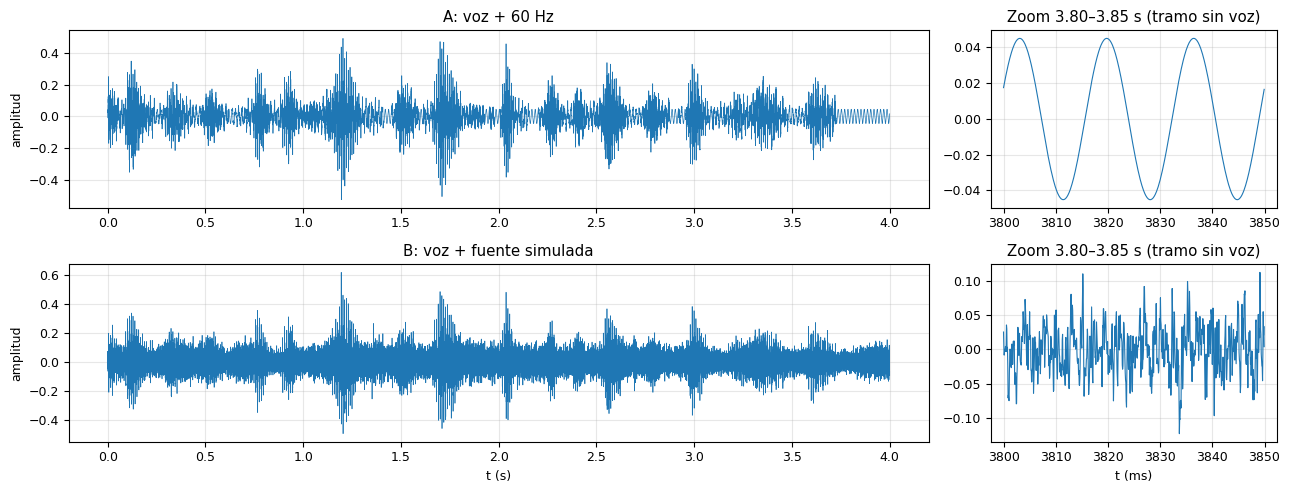

RMS de los últimos 250 ms (sin voz):  A = 0.0318   B = 0.0429
Un seno de amplitud a tiene RMS a/√2. En A: a ≈ 0.0450


In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [3, 1]})
for i, (x, nom) in enumerate(((xA, 'A: voz + 60 Hz'), (xB, 'B: voz + fuente simulada'))):
    ax[i, 0].plot(t, x, lw=.5); ax[i, 0].set_title(nom); ax[i, 0].set_ylabel('amplitud')
    sel = (t >= 3.80) & (t < 3.85)
    ax[i, 1].plot(1000*t[sel], x[sel], lw=.8); ax[i, 1].set_title('Zoom 3.80–3.85 s (tramo sin voz)')
ax[1, 0].set_xlabel('t (s)'); ax[1, 1].set_xlabel('t (ms)')
plt.tight_layout(); plt.show()

# Energía por tramos de 25 ms: localiza voz y silencios
fl = 400; E = lambda x: np.array([np.sqrt(np.mean(x[i:i+fl]**2)) for i in range(0, len(x)-fl+1, fl)])
print('RMS de los últimos 250 ms (sin voz):  A = %.4f   B = %.4f' % (np.sqrt(np.mean(xA[-4000:]**2)), np.sqrt(np.mean(xB[-4000:]**2))))
print('Un seno de amplitud a tiene RMS a/√2. En A: a ≈ %.4f' % (np.sqrt(2)*np.sqrt(np.mean(xA[-4000:]**2))))

### 2.2 FFT por segmentos con ventana Hann (longitud ajustable)



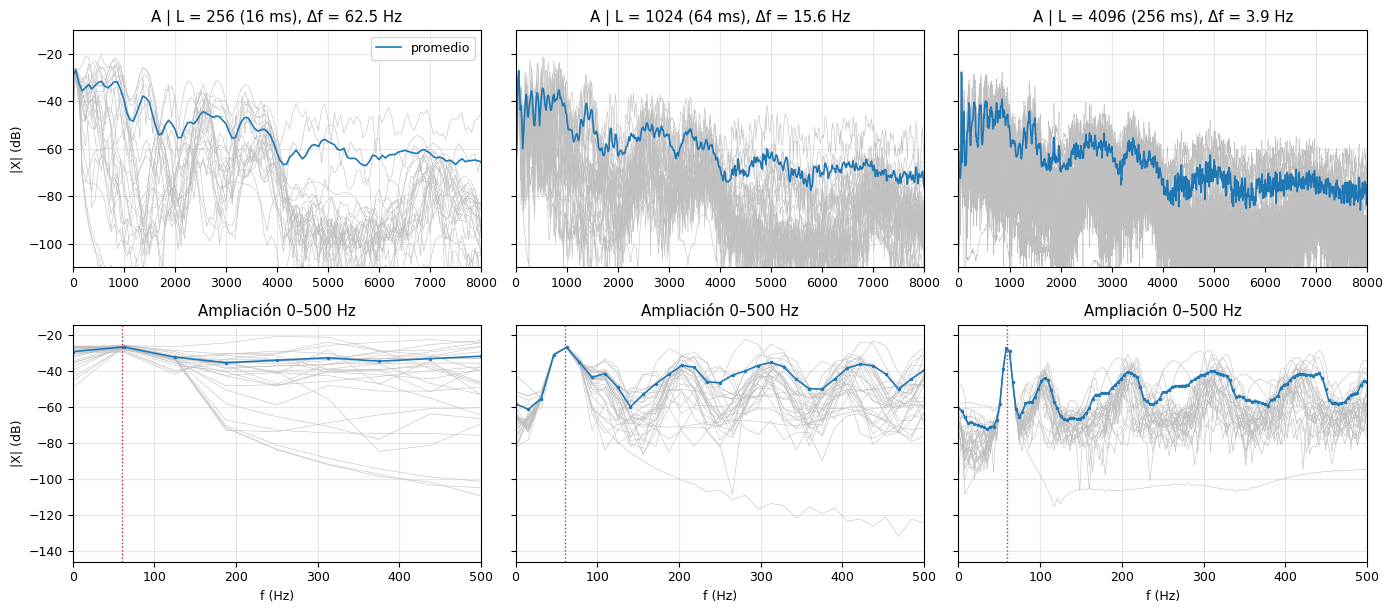

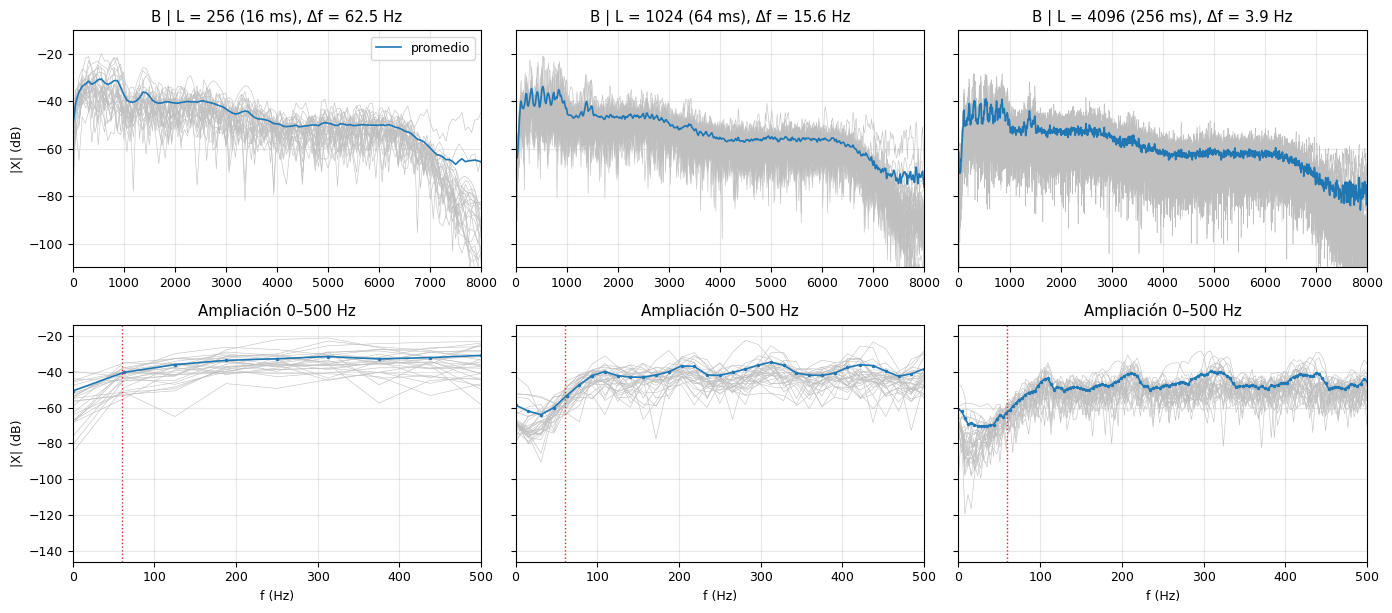

In [ ]:
def ventana_analisis(L, tipo='hann'):
    n = np.arange(L)
    return 0.5 - 0.5*np.cos(2*np.pi*n/L) if tipo == 'hann' else np.ones(L)   # Hann periódica (análisis)

def espectro_segmentos(x, L=1024, solape=0.5, ventana='hann', fs=fs):
    w = ventana_analisis(L, ventana); hop = int(L*(1-solape))
    ini = np.arange(0, len(x)-L+1, hop)
    S = np.array([np.abs(np.fft.rfft(x[i:i+L]*w)) * 2/np.sum(w) for i in ini])   # magnitud por segmento
    f = np.fft.rfftfreq(L, 1/fs)
    S_prom = np.sqrt(np.mean(S**2, axis=0))                                        # promedio de potencia
    return f, S, S_prom, ini/fs

dB = lambda m: 20*np.log10(np.maximum(m, 1e-7))

def figura_espectros(x, nombre, Ls=(256, 1024, 4096), fzoom=500, archivo=None):
    fig, ax = plt.subplots(2, len(Ls), figsize=(14, 6.2), sharey='row')
    for j, L in enumerate(Ls):
        f, S, Sp, _ = espectro_segmentos(x, L)
        for k in range(0, len(S), max(1, len(S)//25)):
            ax[0, j].plot(f, dB(S[k]), color='0.75', lw=.4); ax[1, j].plot(f, dB(S[k]), color='0.75', lw=.4)
        ax[0, j].plot(f, dB(Sp), color='tab:blue', lw=1.2, label='promedio')
        ax[1, j].plot(f, dB(Sp), color='tab:blue', lw=1.2, marker='.', ms=3)
        ax[0, j].set_title(f'{nombre} | L = {L} ({1000*L/fs:.0f} ms), Δf = {fs/L:.1f} Hz')
        ax[1, j].set_xlim(0, fzoom); ax[1, j].set_title(f'Ampliación 0–{fzoom} Hz')
        ax[0, j].set_xlim(0, fs/2); ax[1, j].set_xlabel('f (Hz)')
        ax[1, j].axvline(60, color='tab:red', ls=':', lw=1)
    ax[0, 0].set_ylabel('|X| (dB)'); ax[1, 0].set_ylabel('|X| (dB)'); ax[0, 0].legend(loc='upper right')
    ax[0, 0].set_ylim(-110, -10)
    plt.tight_layout()
    if archivo: fig.savefig(archivo, dpi=150, bbox_inches='tight')
    plt.show()

figura_espectros(xA, 'A', archivo='figuras/espectros_A.png')
figura_espectros(xB, 'B', archivo='figuras/espectros_B.png')



### 2.3 Fuga espectral: ventana rectangular vs Hann

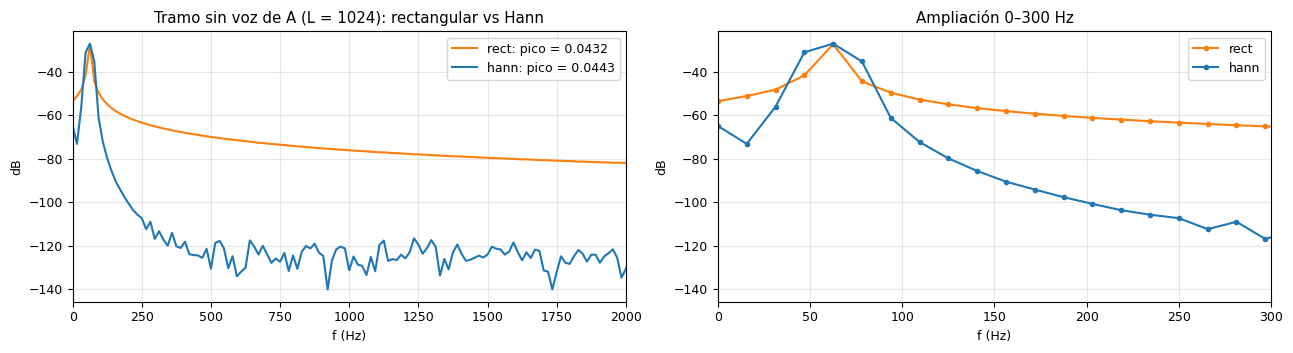

rect : nivel a 500 Hz del tono =  -43.7 dB respecto al pico
hann : nivel a 500 Hz del tono = -103.2 dB respecto al pico


In [ ]:
seg = xA[-4096:-4096+1024]                 # tramo final de A: solo el tono de 60 Hz (60/15.625 = 3.84 bins, no cae en un bin)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for tipo, col in (('rect', 'tab:orange'), ('hann', 'tab:blue')):
    w = ventana_analisis(1024, tipo); f = np.fft.rfftfreq(1024, 1/fs)
    X = np.abs(np.fft.rfft(seg*w))*2/np.sum(w)
    ax[0].plot(f, dB(X), color=col, label=f'{tipo}: pico = {X.max():.4f}')
    ax[1].plot(f, dB(X), color=col, marker='.', label=tipo)
ax[0].set_xlim(0, 2000); ax[0].set_title('Tramo sin voz de A (L = 1024): rectangular vs Hann'); ax[0].legend()
ax[1].set_xlim(0, 300); ax[1].set_title('Ampliación 0–300 Hz'); ax[1].legend()
for a in ax: a.set_xlabel('f (Hz)'); a.set_ylabel('dB')
plt.tight_layout(); plt.savefig('figuras/fuga.png', dpi=150, bbox_inches='tight'); plt.show()

# Piso de fuga a 500 Hz del tono
f = np.fft.rfftfreq(1024, 1/fs); i5 = np.argmin(abs(f-560))
for tipo in ('rect', 'hann'):
    w = ventana_analisis(1024, tipo); X = np.abs(np.fft.rfft(seg*w))*2/np.sum(w)
    print(f'{tipo:5s}: nivel a 500 Hz del tono = {dB(X[i5]) - dB(X.max()):6.1f} dB respecto al pico')



### 2.4 Espectrograma (STFT Hann, L = 1024, 75 % de solape)

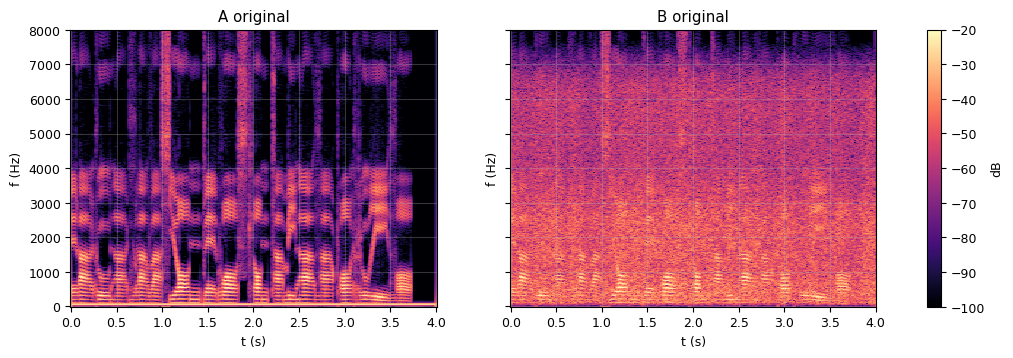

In [ ]:
def espectrograma(ax, x, titulo, L=1024):
    f, tt, Z = signal.stft(x, fs, window='hann', nperseg=L, noverlap=3*L//4)
    im = ax.pcolormesh(tt, f, dB(np.abs(Z)*2), shading='auto', vmin=-100, vmax=-20, cmap='magma')
    ax.set_title(titulo); ax.set_ylabel('f (Hz)'); return im
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
espectrograma(ax[0], xA, 'A original'); im = espectrograma(ax[1], xB, 'B original')
for a in ax: a.set_xlabel('t (s)')
fig.colorbar(im, ax=ax, label='dB'); plt.savefig('figuras/espectrograma_orig.png', dpi=150, bbox_inches='tight'); plt.show()

### 2.5 Diagnóstico cuantitativo y una referencia *aproximada* de la voz




Tono estimado: f = 60.000 Hz, amplitud = 0.0450 (-26.9 dBFS)
RMS en el tramo final (sin voz): A = 0.0318 -> tras restar el tono = 0.00019 (-44.3 dB)
Correlación entre ruido estimado de B y voz estimada: -0.0070  (≈0 -> la suposición es consistente)
SNR estimada de entrada:  A = 4.02 dB   B = 1.62 dB
90 % de la energía:  voz por debajo de   1391 Hz | ruido B por debajo de   3305 Hz
95 % de la energía:  voz por debajo de   2391 Hz | ruido B por debajo de   4828 Hz
99 % de la energía:  voz por debajo de   3516 Hz | ruido B por debajo de   6211 Hz
Energía del ruido B: < 70 Hz = 0.1 %,  > 3.5 kHz = 8.9 %
Energía de la voz:   < 85 Hz = 0.09 %,  > 3.5 kHz = 1.02 %


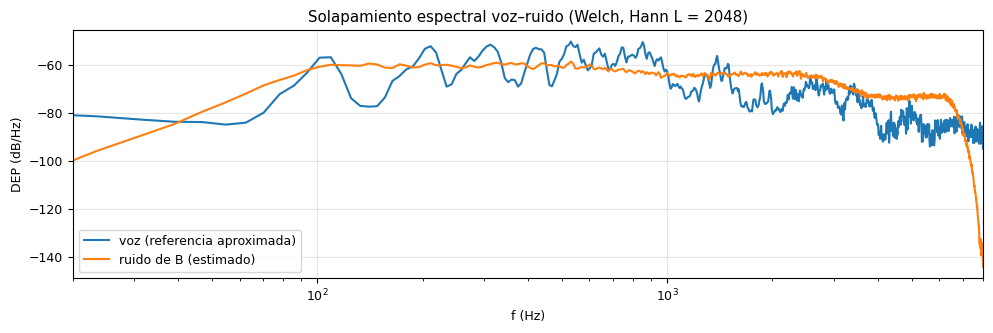

F0 de la voz (percentiles 5/50/95): 83 / 103 / 110 Hz


In [ ]:
n = np.arange(Nx)
mejor = None
for f0 in np.arange(59.90, 60.101, 0.005):                       # búsqueda fina de la frecuencia del tono
    Mx = np.c_[np.cos(2*np.pi*f0*n/fs), np.sin(2*np.pi*f0*n/fs)]
    c = np.linalg.lstsq(Mx, xA, rcond=None)[0]; r = np.sum((xA - Mx@c)**2)
    if mejor is None or r < mejor[0]: mejor = (r, f0, c, Mx@c)
_, f_hum, c_hum, hum_est = mejor
v_ref = xA - hum_est                 # voz aproximada
wA_ref = hum_est                     # interferencia de A
wB_ref = xB - v_ref                  # ruido aproximado de B
rms = lambda x: np.sqrt(np.mean(x**2))
print(f'Tono estimado: f = {f_hum:.3f} Hz, amplitud = {np.hypot(*c_hum):.4f} ({20*np.log10(np.hypot(*c_hum)):.1f} dBFS)')
print(f'RMS en el tramo final (sin voz): A = {rms(xA[-4000:]):.4f} -> tras restar el tono = {rms(v_ref[-4000:]):.5f} ({20*np.log10(rms(v_ref[-4000:])/rms(xA[-4000:])):.1f} dB)')
print(f'Correlación entre ruido estimado de B y voz estimada: {np.corrcoef(wB_ref, v_ref)[0,1]:+.4f}  (≈0 -> la suposición es consistente)')
print(f'SNR estimada de entrada:  A = {10*np.log10(np.sum(v_ref**2)/np.sum(wA_ref**2)):.2f} dB   B = {10*np.log10(np.sum(v_ref**2)/np.sum(wB_ref**2)):.2f} dB')

# Ocupación espectral de voz y ruido (Welch, Hann L = 2048)
f, Pv = signal.welch(v_ref, fs, window='hann', nperseg=2048); _, Pw = signal.welch(wB_ref, fs, window='hann', nperseg=2048)
cv, cw = np.cumsum(Pv)/Pv.sum(), np.cumsum(Pw)/Pw.sum()
for p in (0.90, 0.95, 0.99):
    print(f'{int(p*100)} % de la energía:  voz por debajo de {f[np.searchsorted(cv, p)]:6.0f} Hz | ruido B por debajo de {f[np.searchsorted(cw, p)]:6.0f} Hz')
print(f'Energía del ruido B: < 70 Hz = {100*cw[np.searchsorted(f,70)]:.1f} %,  > 3.5 kHz = {100*(1-cw[np.searchsorted(f,3500)]):.1f} %')
print(f'Energía de la voz:   < 85 Hz = {100*cv[np.searchsorted(f,85)]:.2f} %,  > 3.5 kHz = {100*(1-cv[np.searchsorted(f,3500)]):.2f} %')

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.semilogx(f[1:], 10*np.log10(Pv[1:]), label='voz (referencia aproximada)')
ax.semilogx(f[1:], 10*np.log10(Pw[1:]), label='ruido de B (estimado)')
_, PA = signal.welch(xA, fs, window='hann', nperseg=8192)
ax.set_xlabel('f (Hz)'); ax.set_ylabel('DEP (dB/Hz)'); ax.set_xlim(20, 8000)
ax.set_title('Solapamiento espectral voz–ruido (Welch, Hann L = 2048)'); ax.legend()
plt.tight_layout(); plt.savefig('figuras/solape.png', dpi=150, bbox_inches='tight'); plt.show()

# F0 de la voz por autocorrelación en tramos con voz
f0s = []
for i in range(0, Nx-1024, 512):
    s_ = v_ref[i:i+1024]*np.hanning(1024)
    if rms(s_) < 0.02: continue
    r_ = np.correlate(s_, s_, 'full')[1023:]; lo, hi = fs//400, fs//60; k = lo + np.argmax(r_[lo:hi])
    if r_[k] > 0.3*r_[0]: f0s.append(fs/k)
print('F0 de la voz (percentiles 5/50/95): %.0f / %.0f / %.0f Hz' % tuple(np.percentile(f0s, [5, 50, 95])))

## 3. Diseño FIR por el método de ventanas

### 3.1 Respuesta ideal, truncamiento y ventana Hann



max |h_propio - firwin| (PB) = 3.469446951953614e-18
max |h_propio - firwin| (PA) = 1.43982048506075e-16


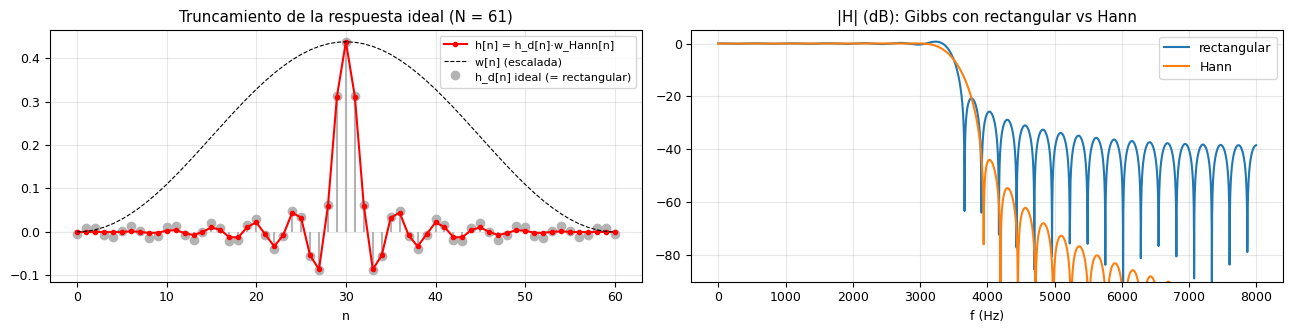

In [ ]:
def ventana_hann_diseno(N):
    n = np.arange(N); return 0.5 - 0.5*np.cos(2*np.pi*n/(N-1))      # Hann simétrica (diseño)

def fir_ventana(tipo, fc, N, fs=fs, ventana='hann'):
    assert N % 2 == 1, 'N impar -> FIR tipo I (necesario para el pasa-altas)'
    M = (N-1)//2; n = np.arange(N) - M; wc = 2*np.pi*fc/fs
    hd = (wc/np.pi)*np.sinc(wc*n/np.pi)                              # pasa-bajas ideal desplazado
    if tipo == 'pa': hd = -hd; hd[M] += 1.0                          # pasa-altas = δ[n-M] - pasa-bajas
    w = ventana_hann_diseno(N) if ventana == 'hann' else np.ones(N)
    return hd*w, hd

# Verificación contra scipy.signal.firwin (mismo método de ventanas) -> diferencia solo por la normalización de ganancia de firwin
h1, _ = fir_ventana('pb', 3500, 161); h2 = signal.firwin(161, 3500, window='hann', fs=fs, scale=False)
print('max |h_propio - firwin| (PB) =', np.max(abs(h1-h2)))
h1, _ = fir_ventana('pa', 85, 1281); h2 = signal.firwin(1281, 85, window='hann', fs=fs, pass_zero=False, scale=False)
print('max |h_propio - firwin| (PA) =', np.max(abs(h1-h2)))

# Efecto de la ventana de truncamiento: rectangular (Gibbs) vs Hann, ejemplo PB fc = 3.5 kHz, N = 61
N_ = 61; hh, hd = fir_ventana('pb', 3500, N_); hr, _ = fir_ventana('pb', 3500, N_, ventana='rect')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].stem(np.arange(N_), hd, linefmt='0.7', markerfmt='o', basefmt=' ', label='h_d[n] ideal (= rectangular)')
ax[0].plot(np.arange(N_), hh, 'r.-', label='h[n] = h_d[n]·w_Hann[n]'); ax[0].plot(np.arange(N_), ventana_hann_diseno(N_)*hd.max(), 'k--', lw=.8, label='w[n] (escalada)')
ax[0].set_title('Truncamiento de la respuesta ideal (N = 61)'); ax[0].legend(fontsize=8); ax[0].set_xlabel('n')
for h_, nom in ((hr, 'rectangular'), (hh, 'Hann')):
    w_, H_ = signal.freqz(h_, 1, 4096, fs=fs); ax[1].plot(w_, dB(abs(H_)), label=nom)
ax[1].set_ylim(-90, 5); ax[1].set_title('|H| (dB): Gibbs con rectangular vs Hann'); ax[1].set_xlabel('f (Hz)'); ax[1].legend()
plt.tight_layout(); plt.show()



### 3.2 Audio A — elección del pasa-altas (rechazo de 60 Hz)


  fc     N    Δf≈ |H(60)| dB  |H(85)| |H(100)| |H(110)| retardo ms
  70   401  123.7       -8.5     -3.3     -1.6     -0.8       12.5
  70   801   61.9      -11.6     -1.6     -0.1      0.1       25.0
  70  1281   38.7      -16.5     -0.4      0.0     -0.0       40.0
  70  1601   31.0      -20.7     -0.1     -0.0      0.0       50.0
  85   401  123.7      -13.5     -6.0     -3.3     -2.1       12.5
  85   801   61.9      -27.6     -6.0     -1.6     -0.4       25.0
  85  1281   38.7      -43.9     -6.0     -0.4      0.1       40.0
  85  1601   31.0      -58.1     -6.0     -0.1      0.0       50.0
 100   401  123.7      -20.8     -9.9     -6.0     -4.1       12.5
 100   801   61.9      -43.8    -15.6     -6.0     -2.6       25.0
 100  1281   38.7      -56.3    -26.1     -6.0     -1.4       40.0
 100  1601   31.0      -62.0    -39.1     -6.0     -0.8       50.0


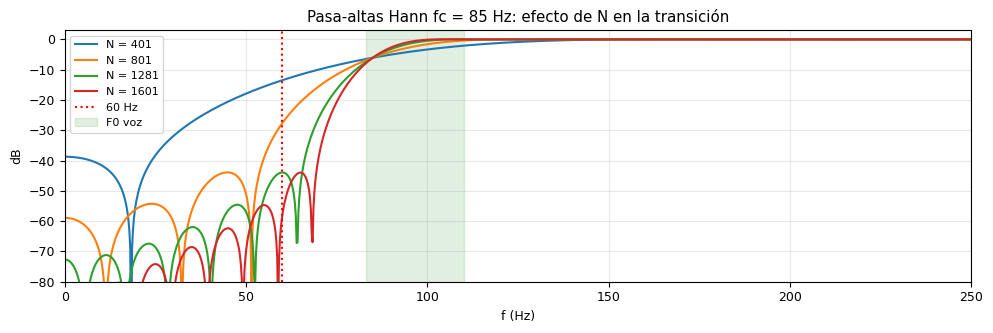

In [ ]:
def gan_dB(h, f): return dB(abs(signal.freqz(h, 1, worN=[2*np.pi*f/fs])[1][0]))

print(f"{'fc':>4} {'N':>5} {'Δf≈':>6} {'|H(60)| dB':>10} {'|H(85)|':>8} {'|H(100)|':>8} {'|H(110)|':>8} {'retardo ms':>10}")
for fc in (70, 85, 100):
    for N in (401, 801, 1281, 1601):
        h, _ = fir_ventana('pa', fc, N)
        print(f'{fc:4d} {N:5d} {3.1*fs/N:6.1f} {gan_dB(h,60):10.1f} {gan_dB(h,85):8.1f} {gan_dB(h,100):8.1f} {gan_dB(h,110):8.1f} {1000*(N-1)/2/fs:10.1f}')

fig, ax = plt.subplots(figsize=(10, 3.4))
for N in (401, 801, 1281, 1601):
    h, _ = fir_ventana('pa', 85, N); f_, H_ = signal.freqz(h, 1, 2**15, fs=fs)
    ax.plot(f_, dB(abs(H_)), label=f'N = {N}')
ax.axvline(60, color='r', ls=':', label='60 Hz'); ax.axvspan(83, 110, color='g', alpha=.12, label='F0 voz')
ax.set_xlim(0, 250); ax.set_ylim(-80, 3); ax.set_xlabel('f (Hz)'); ax.set_ylabel('dB')
ax.set_title('Pasa-altas Hann fc = 85 Hz: efecto de N en la transición'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figuras/A_barrido_N.png', dpi=150, bbox_inches='tight'); plt.show()




### 3.3 Audio B — elección del pasa-bajas y del pasa-altas


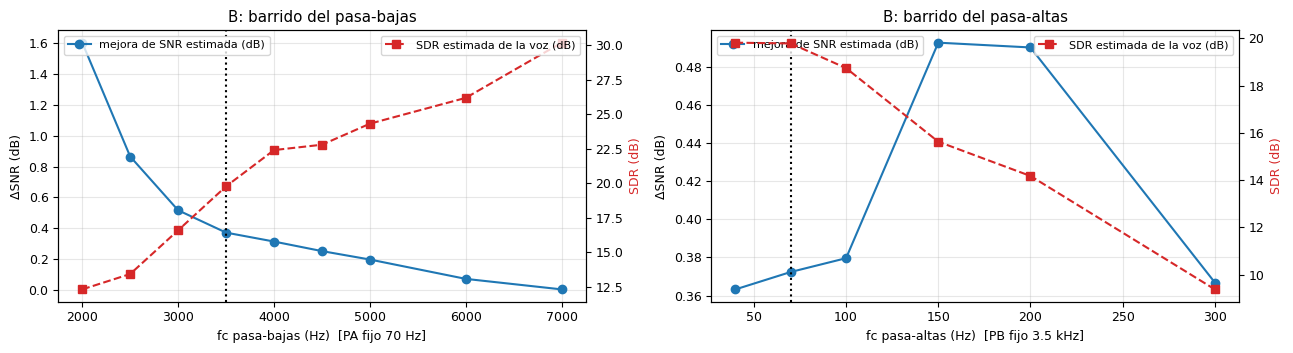

fc_PB  ΔSNR   SDR   atenuación ruido
 2000  1.60   12.3  -1.87 dB
 2500  0.86   13.4  -1.09 dB
 3000  0.52   16.6  -0.62 dB
 3500  0.37   19.8  -0.43 dB
 4000  0.31   22.4  -0.34 dB
 4500  0.25   22.8  -0.28 dB
 5000  0.20   24.3  -0.22 dB
 6000  0.07   26.2  -0.09 dB
 7000  0.01   30.2  -0.01 dB
fc_PA  ΔSNR   SDR
   40  0.36   19.8
   70  0.37   19.8
  100  0.38   18.7
  150  0.49   15.6
  200  0.49   14.2
  300  0.37    9.4

Longitud del pasa-bajas B (fc = 3.5 kHz):
  N =  41: Δf ≈  1210 Hz, |H(4 kHz)| =  -27.7 dB, ΔSNR = 0.40 dB, SDR = 20.1 dB
  N =  81: Δf ≈   612 Hz, |H(4 kHz)| =  -58.1 dB, ΔSNR = 0.38 dB, SDR = 19.9 dB
  N = 161: Δf ≈   308 Hz, |H(4 kHz)| =  -67.9 dB, ΔSNR = 0.37 dB, SDR = 19.8 dB
  N = 321: Δf ≈   155 Hz, |H(4 kHz)| =  -85.9 dB, ΔSNR = 0.37 dB, SDR = 19.7 dB


In [ ]:
def aplicar_fir(h, x):
    """Filtrado CAUSAL con lfilter + compensación del retardo constante D = (N-1)/2 (fase lineal)."""
    D = (len(h)-1)//2
    return signal.lfilter(h, 1.0, np.r_[x, np.zeros(D)])[D:]

def metricas(filtro, v=v_ref, w=None):
    """Por linealidad, filtro(x) = filtro(v) + filtro(w): se miden por separado (referencia APROXIMADA)."""
    yv, yw = filtro(v), filtro(w)
    return dict(snr_in=10*np.log10(np.sum(v**2)/np.sum(w**2)),
                snr_out=10*np.log10(np.sum(yv**2)/np.sum(yw**2)),
                att=10*np.log10(np.sum(yw**2)/np.sum(w**2)),
                sdr=10*np.log10(np.sum(v**2)/np.sum((yv-v)**2)),
                sdr_mag=sdr_mag(yv, v))

def sdr_mag(yv, v, L=1024):
    """Igual que la SDR pero comparando solo |STFT| (insensible a la fase): ¿cambió el contenido espectral de la voz?"""
    V = np.abs(signal.stft(v, fs, window='hann', nperseg=L)[2]); Y = np.abs(signal.stft(yv, fs, window='hann', nperseg=L)[2])
    return 10*np.log10(np.sum(V**2)/np.sum((Y-V)**2))

hPA_B70, _ = fir_ventana('pa', 70, 801)
fcs = [2000, 2500, 3000, 3500, 4000, 4500, 5000, 6000, 7000]
res = []
for fc in fcs:
    hpb, _ = fir_ventana('pb', fc, 161); h = np.convolve(hpb, hPA_B70)
    res.append(metricas(lambda x: aplicar_fir(h, x), w=wB_ref))
fchp = [40, 70, 100, 150, 200, 300]; res2 = []
hPB_B35, _ = fir_ventana('pb', 3500, 161)
for fc in fchp:
    hpa, _ = fir_ventana('pa', fc, 801); h = np.convolve(hPB_B35, hpa)
    res2.append(metricas(lambda x: aplicar_fir(h, x), w=wB_ref))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, xs, R, xl in ((ax[0], fcs, res, 'fc pasa-bajas (Hz)  [PA fijo 70 Hz]'), (ax[1], fchp, res2, 'fc pasa-altas (Hz)  [PB fijo 3.5 kHz]')):
    a.plot(xs, [r['snr_out'] - r['snr_in'] for r in R], 'o-', label='mejora de SNR estimada (dB)')
    a2 = a.twinx(); a2.plot(xs, [r['sdr'] for r in R], 's--', color='tab:red', label='SDR estimada de la voz (dB)'); a2.grid(False)
    a.set_xlabel(xl); a.set_ylabel('ΔSNR (dB)'); a2.set_ylabel('SDR (dB)', color='tab:red')
    a.legend(loc='upper left', fontsize=8); a2.legend(loc='upper right', fontsize=8)
ax[0].axvline(3500, color='k', ls=':'); ax[1].axvline(70, color='k', ls=':')
ax[0].set_title('B: barrido del pasa-bajas'); ax[1].set_title('B: barrido del pasa-altas')
plt.tight_layout(); plt.savefig('figuras/B_barrido_fc.png', dpi=150, bbox_inches='tight'); plt.show()
print('fc_PB  ΔSNR   SDR   atenuación ruido')
for fc, r in zip(fcs, res): print(f'{fc:5d} {r["snr_out"]-r["snr_in"]:5.2f} {r["sdr"]:6.1f} {r["att"]:6.2f} dB')
print('fc_PA  ΔSNR   SDR')
for fc, r in zip(fchp, res2): print(f'{fc:5d} {r["snr_out"]-r["snr_in"]:5.2f} {r["sdr"]:6.1f}')

print('\nLongitud del pasa-bajas B (fc = 3.5 kHz):')
for N in (41, 81, 161, 321):
    hpb, _ = fir_ventana('pb', 3500, N); h = np.convolve(hpb, hPA_B70); r = metricas(lambda x: aplicar_fir(h, x), w=wB_ref)
    print(f'  N = {N:3d}: Δf ≈ {3.1*fs/N:5.0f} Hz, |H(4 kHz)| = {gan_dB(hpb,4000):6.1f} dB, ΔSNR = {r["snr_out"]-r["snr_in"]:.2f} dB, SDR = {r["sdr"]:.1f} dB')



### 3.4 Filtros FIR finales: h[n], H(z), ecuación en diferencias, ceros y respuesta en frecuencia

In [ ]:
DIS = {'A': dict(pb=(7000, 101), pa=(85, 1281)), 'B': dict(pb=(3500, 161), pa=(70, 801))}
FIR = {}
t0 = time.time()
for k, d in DIS.items():
    hpb, _ = fir_ventana('pb', *d['pb']); hpa, _ = fir_ventana('pa', *d['pa'])
    FIR[k] = dict(pb=hpb, pa=hpa, total=np.convolve(hpb, hpa),
                  s_pb=SistemaFIR(hpb, f'{k}: pasa-bajas Hann fc={d["pb"][0]} Hz, N={d["pb"][1]}'),
                  s_pa=SistemaFIR(hpa, f'{k}: pasa-altas Hann fc={d["pa"][0]} Hz, N={d["pa"][1]}'))
print(f'ceros calculados en {time.time()-t0:.1f} s\n')
for k in FIR:
    print(FIR[k]['s_pb'].resumen(fs)); print(); print(FIR[k]['s_pa'].resumen(fs)); print()
    ht = FIR[k]['total']
    print(f'Cascada {k}: w[n] = Σ hPB[k]x[n-k];  y[n] = Σ hPA[k]w[n-k]  ⇔  y[n] = Σ h[k]x[n-k] con h = hPB*hPA '
          f'(N = {len(ht)}, retardo total {(len(ht)-1)//2} muestras = {1000*(len(ht)-1)/2/fs:.1f} ms)\n')

# Verificación de la interpretación geométrica (producto de distancias a los ceros) contra freqz
for k in FIR:
    for c in ('s_pb', 's_pa'):
        s = FIR[k][c]
        for f0 in (60, 1000, 3000, 7500):
            w0 = 2*np.pi*f0/fs; Hg = s.H_geometrica(w0); Hf = s.H(w0)
            print(f'{s.nombre[:30]:30s} f = {f0:5d} Hz: |H| geom = {abs(Hg):.3e}  freqz = {abs(Hf):.3e}')

ceros calculados en 13.9 s

--- A: pasa-bajas Hann fc=7000 Hz, N=101 ---
N = 101 coeficientes (orden 100),  retardo de grupo = (N-1)/2 = 50 muestras = 3.12 ms
Simetría h[n] = h[N-1-n]: True  -> fase lineal tipo I
H(z) = (+2.4527e-06)z^-1 + (+5.1295e-20)z^-2 + (-2.2953e-05)z^-3 + ... + (+8.7500e-01)z^-50 + ... + (+2.4527e-06)z^-99
Ecuación en diferencias: y[n] = Σ_(k=0..100) h[k]·x[n-k]   (no recursiva, sin realimentación)
Polos: 100 en z = 0  -> ESTABLE siempre
Ceros: 99 en total | sobre |z|≈1 (±1%): 10 | dentro: 45 | fuera: 44
Suma h = H(1) = 1.0000   Σh(-1)^n = H(-1) = -0.0003

--- A: pasa-altas Hann fc=85 Hz, N=1281 ---
N = 1281 coeficientes (orden 1280),  retardo de grupo = (N-1)/2 = 640 muestras = 40.00 ms
Simetría h[n] = h[N-1-n]: True  -> fase lineal tipo I
H(z) = (-1.8438e-09)z^-1 + (-7.6992e-09)z^-2 + (-1.8035e-08)z^-3 + ... + (+9.8938e-01)z^-640 + ... + (-1.8438e-09)z^-1279
Ecuación en diferencias: y[n] = Σ_(k=0..1280) h[k]·x[n-k]   (no recursiva, sin realimentación)
Polos: 1

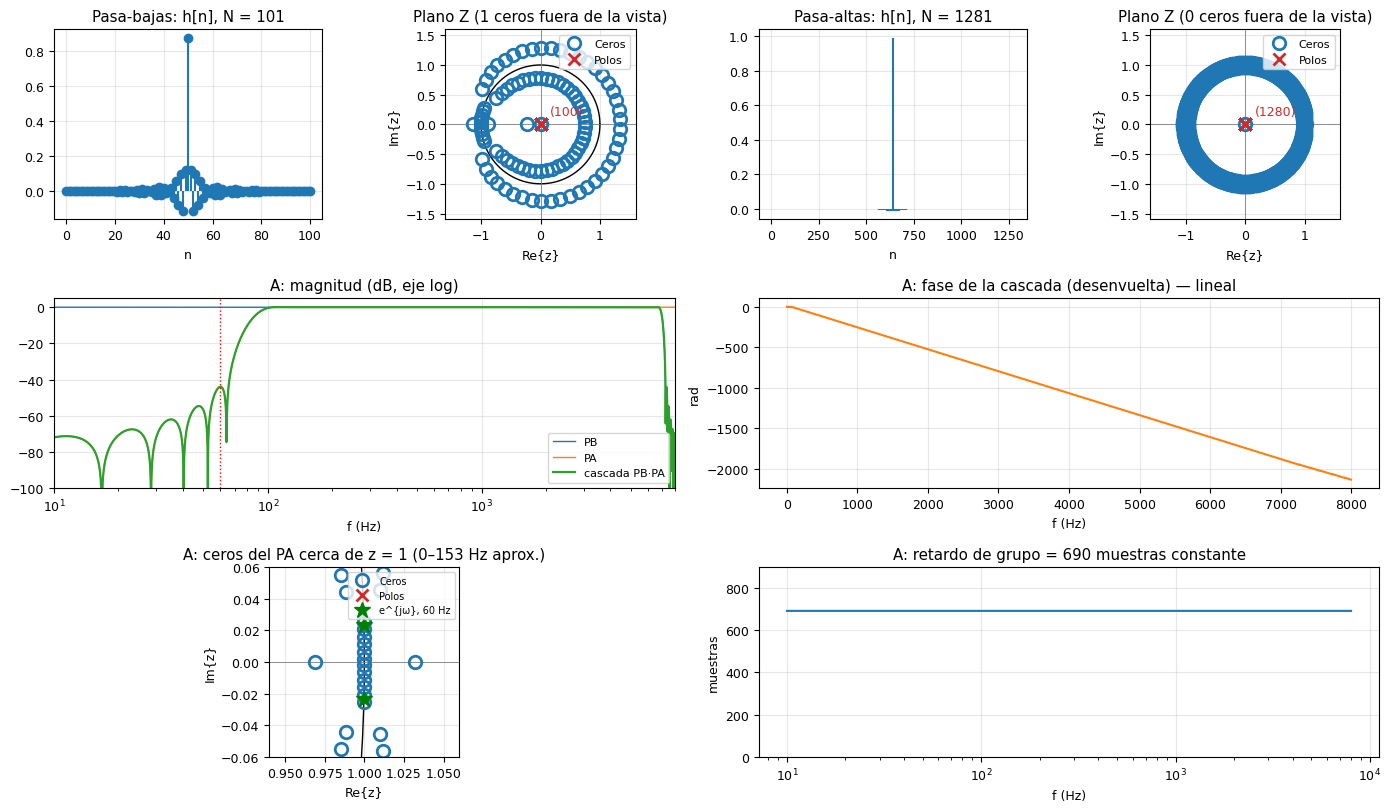

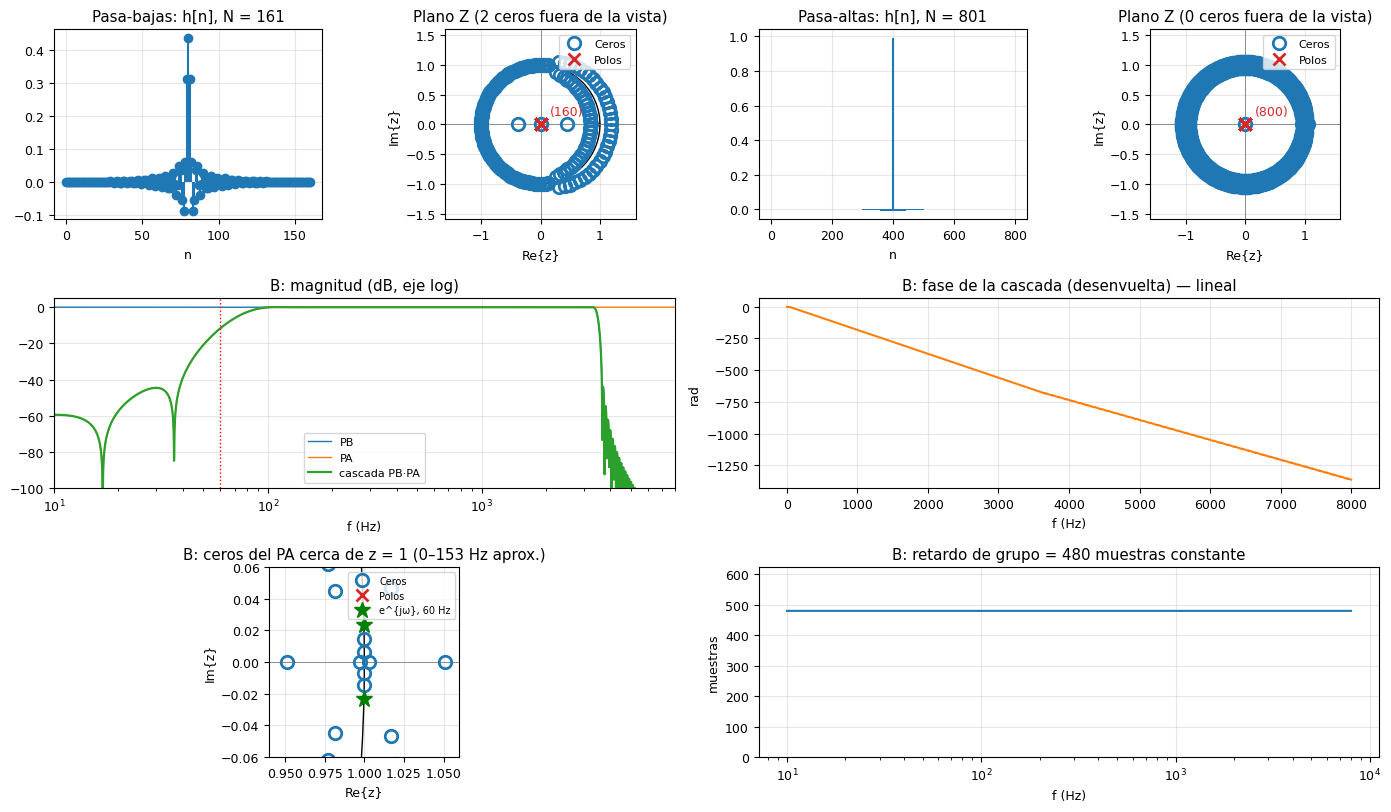

In [ ]:
def figura_fir(k, archivo=None):
    d = FIR[k]; f = np.linspace(0, fs/2, 2**15); fl = np.geomspace(10, 0.999*fs/2, 4000)
    fig = plt.figure(figsize=(14, 8.2)); gs = GridSpec(3, 4, figure=fig)
    for j, (c, hh) in enumerate((('s_pb', d['pb']), ('s_pa', d['pa']))):
        s = d[c]
        a = fig.add_subplot(gs[0, 2*j]); a.stem(np.arange(len(hh)), hh, basefmt=' ', markerfmt=' ' if len(hh) > 300 else 'o')
        a.set_title(('Pasa-bajas' if c == 's_pb' else 'Pasa-altas') + f': h[n], N = {len(hh)}'); a.set_xlabel('n')
        a = fig.add_subplot(gs[0, 2*j+1]); dibujar_plano(a, s)
        fuera = np.sum(np.abs(np.array(s.ceros)) > 1.6); a.set_title(f'Plano Z ({fuera} ceros fuera de la vista)')
    a = fig.add_subplot(gs[1, :2])
    for hh, nom in ((d['pb'], 'PB'), (d['pa'], 'PA'), (d['total'], 'cascada PB·PA')):
        _, H_ = signal.freqz(hh, 1, worN=2*np.pi*fl/fs); a.semilogx(fl, dB(abs(H_)), label=nom, lw=1.6 if 'cascada' in nom else 1)
    a.axvline(60, color='r', ls=':', lw=1); a.set_ylim(-100, 5); a.set_xlim(10, fs/2); a.legend(fontsize=8)
    a.set_title(f'{k}: magnitud (dB, eje log)'); a.set_xlabel('f (Hz)')
    a = fig.add_subplot(gs[1, 2:]); _, H_ = signal.freqz(d['total'], 1, worN=2*np.pi*f/fs)
    a.plot(f, np.unwrap(np.angle(H_)), color='tab:orange'); a.set_title(f'{k}: fase de la cascada (desenvuelta) — lineal')
    a.set_xlabel('f (Hz)'); a.set_ylabel('rad')
    a = fig.add_subplot(gs[2, :2]); plano_zoom(a, d['s_pa'], 1+0j, 0.06, f'{k}: ceros del PA cerca de z = 1 (0–{fs*0.06/(2*np.pi):.0f} Hz aprox.)')
    t60 = 2*np.pi*60/fs; a.plot(np.cos(t60), np.sin(t60), 'g*', ms=12, label='e^{jω}, 60 Hz'); a.plot(np.cos(t60), -np.sin(t60), 'g*', ms=12); a.legend(fontsize=7)
    a = fig.add_subplot(gs[2, 2:]); a.semilogx(fl, grupo_fir(d['total'], fl, fs), label='retardo de grupo')
    a.set_ylim(0, 1.3*(len(d['total'])-1)/2); a.set_title(f'{k}: retardo de grupo = {(len(d["total"])-1)//2} muestras constante'); a.set_xlabel('f (Hz)'); a.set_ylabel('muestras')
    plt.tight_layout()
    if archivo: fig.savefig(archivo, dpi=150, bbox_inches='tight')
    plt.show()
figura_fir('A', 'figuras/FIR_A.png'); figura_fir('B', 'figuras/FIR_B.png')



### 3.5 Filtrado FIR, guardado y escucha


In [ ]:
yA_fir = aplicar_fir(FIR['A']['total'], xA)
yB_fir = aplicar_fir(FIR['B']['total'], xB)
guardar('A_FIR.wav', yA_fir); guardar('B_FIR.wav', yB_fir)
escuchar(xA, 'A original'); escuchar(yA_fir, 'A_FIR (PB 7 kHz + PA 85 Hz)')
escuchar(xB, 'B original'); escuchar(yB_fir, 'B_FIR (PB 3.5 kHz + PA 70 Hz)')
escuchar(xB - yB_fir, 'B: lo que el FIR quitó (original − filtrada)')

  guardado salidas/A_FIR.wav
  guardado salidas/B_FIR.wav
A original


A_FIR (PB 7 kHz + PA 85 Hz)


B original


B_FIR (PB 3.5 kHz + PA 70 Hz)


B: lo que el FIR quitó (original − filtrada)


## 4. Validación con IIR de biblioteca (Butterworth, `scipy.signal`)



In [ ]:
IIR = {}
nA, wnA = signal.buttord(100, 60, 1, 40, fs=fs)
nB, wnB = signal.buttord(3300, 4000, 1, 30, fs=fs)
espec = {'A': dict(pb=(6, 7000), pa=(nA, wnA)), 'B': dict(pb=(nB, wnB), pa=(4, 70))}
for k, e in espec.items():
    IIR[k] = {}
    for c, btype in (('pb', 'lowpass'), ('pa', 'highpass')):
        n_, wn_ = e[c]
        sos = signal.butter(n_, wn_, btype, fs=fs, output='sos'); z, p, kk = signal.butter(n_, wn_, btype, fs=fs, output='zpk')
        IIR[k][c] = dict(sos=sos, sz=SistemaZ(polos=list(p), ceros=list(z), K=kk), orden=n_, fc=float(wn_))
    IIR[k]['sos'] = np.vstack([IIR[k]['pb']['sos'], IIR[k]['pa']['sos']])
    print(f"{k}: PB Butterworth orden {IIR[k]['pb']['orden']} fc = {IIR[k]['pb']['fc']:.0f} Hz | PA Butterworth orden {IIR[k]['pa']['orden']} fc = {IIR[k]['pa']['fc']:.1f} Hz")

print('\nComparación de órdenes con la misma especificación del PA de A (100/60 Hz, 1/40 dB):')
print('  Butterworth', signal.buttord(100, 60, 1, 40, fs=fs)[0], '| Chebyshev I', signal.cheb1ord(100, 60, 1, 40, fs=fs)[0],
      '| Chebyshev II', signal.cheb2ord(100, 60, 1, 40, fs=fs)[0], '| Elíptico', signal.ellipord(100, 60, 1, 40, fs=fs)[0])

# H(z) con el código del Parcial 2 (SistemaZ): polos, ceros, K y estabilidad
print('\n=== A: pasa-altas IIR (SistemaZ del Parcial 2) ===')
print(texto_sistema(IIR['A']['pa']['sz']))

# Fragilidad de la forma directa vs SOS
for k in ('A', 'B'):
    for c in ('pb', 'pa'):
        s = IIR[k][c]['sz']; b, a = signal.sos2tf(IIR[k][c]['sos'])
        f = np.geomspace(10, fs/2, 3000); w = 2*np.pi*f/fs
        _, Hsos = signal.sosfreqz(IIR[k][c]['sos'], worN=w); _, Htf = signal.freqz(b, a, worN=w)
        Hg = s.H(w); nan = ~np.isfinite(Hg)
        nota = f' [{nan.sum()} puntos con f < {f[nan].max():.0f} Hz quedan NaN por el umbral 1e-9 del Parcial 2]' if nan.any() else ''
        print(f'{k}-{c}: |p|máx = {max(abs(np.array(s.polos))):.5f} | error |H_geom - H_sos| = {np.nanmax(abs(Hg-Hsos)):.1e}{nota}'
              f' | error forma directa = {np.max(abs(Htf-Hsos)):.1e} | |p|máx recalculado desde A(z) = {max(abs(np.roots(a))):.5f}')

A: PB Butterworth orden 6 fc = 7000 Hz | PA Butterworth orden 11 fc = 94.0 Hz
B: PB Butterworth orden 15 fc = 3411 Hz | PA Butterworth orden 4 fc = 70.0 Hz

Comparación de órdenes con la misma especificación del PA de A (100/60 Hz, 1/40 dB):
  Butterworth 11 | Chebyshev I 6 | Chebyshev II 6 | Elíptico 4

=== A: pasa-altas IIR (SistemaZ del Parcial 2) ===
H(z) = K · Π(z − zᵢ) / Π(z − pₖ)
K = 0.87831
Ceros : 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
Polos : 0.994-0.0364j, 0.984-0.0331j, 0.976-0.0272j, 0.969-0.0194j, 0.965-0.01j, 0.964, 0.965+0.01j, 0.969+0.0194j, 0.976+0.0272j, 0.984+0.0331j, 0.994+0.0364j
Forma factorizada:
H(z) = 0.8783 · (z − (1))(z − (1))(z − (1))(z − (1))(z − (1))(z − (1))(z − (1))(z − (1))(z − (1))(z − (1))(z −
    (1)) / [(z − (0.994-0.0364j))(z − (0.984-0.0331j))(z − (0.976-0.0272j))(z − (0.969-0.0194j))(z −
    (0.965-0.01j))(z − (0.964))(z − (0.965+0.01j))(z − (0.969+0.0194j))(z − (0.976+0.0272j))(z −
    (0.984+0.0331j))(z − (0.994+0.0364j))]
Numerador B(z) (potencias d

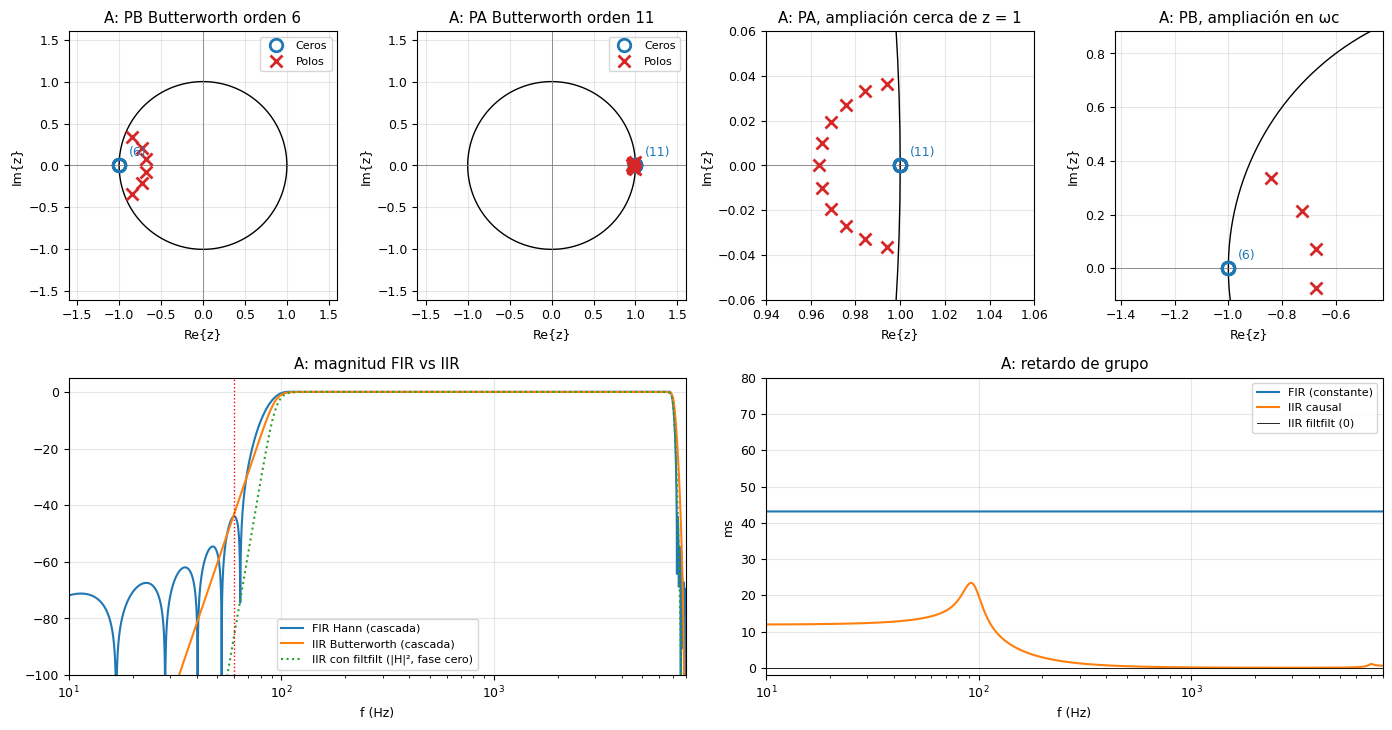

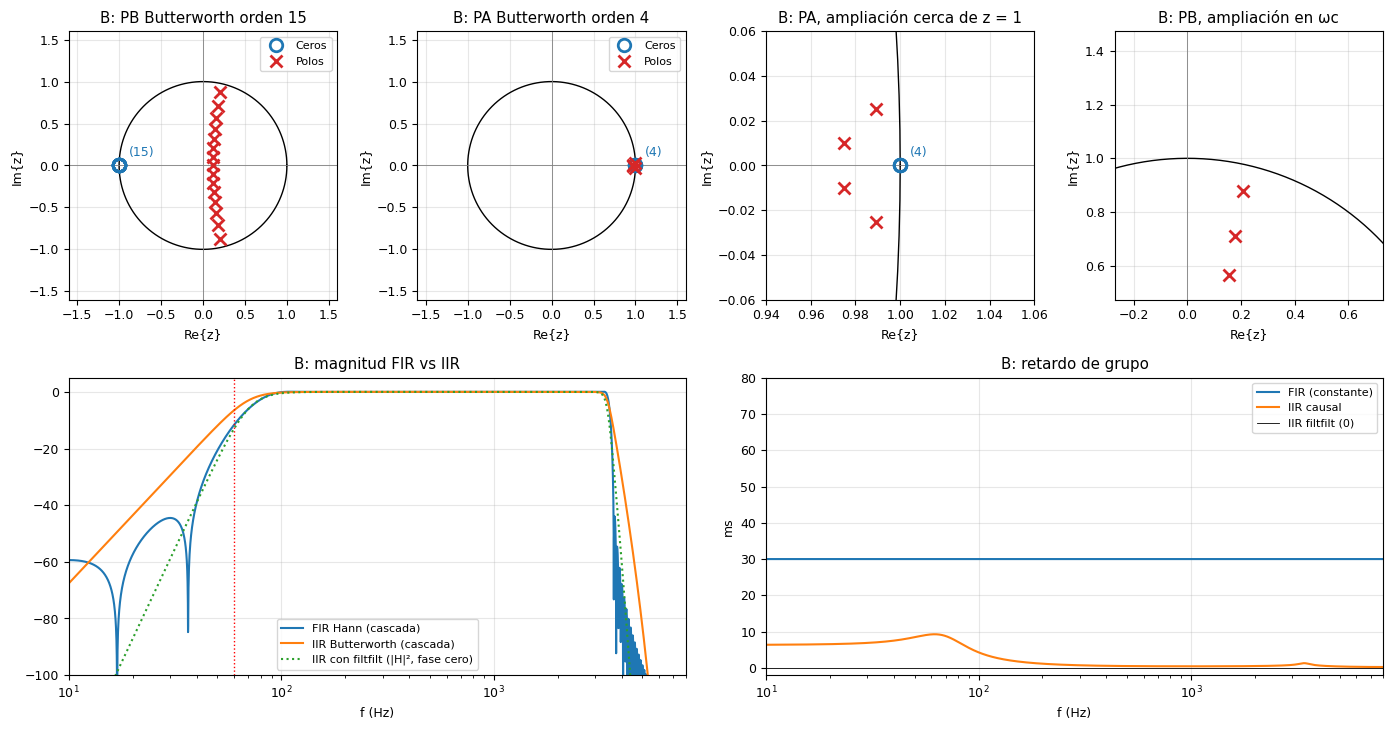

In [ ]:
def figura_iir(k, archivo=None):
    fl = np.geomspace(10, 0.999*fs/2, 4000); w = 2*np.pi*fl/fs
    fig = plt.figure(figsize=(14, 7.4)); gs = GridSpec(2, 4, figure=fig)
    a = fig.add_subplot(gs[0, 0]); dibujar_plano(a, IIR[k]['pb']['sz']); a.set_title(f'{k}: PB Butterworth orden {IIR[k]["pb"]["orden"]}')
    a = fig.add_subplot(gs[0, 1]); dibujar_plano(a, IIR[k]['pa']['sz']); a.set_title(f'{k}: PA Butterworth orden {IIR[k]["pa"]["orden"]}')
    a = fig.add_subplot(gs[0, 2]); plano_zoom(a, IIR[k]['pa']['sz'], 1+0j, 0.06, f'{k}: PA, ampliación cerca de z = 1')
    a = fig.add_subplot(gs[0, 3]); plano_zoom(a, IIR[k]['pb']['sz'], np.exp(1j*2*np.pi*IIR[k]['pb']['fc']/fs), 0.5, f'{k}: PB, ampliación en ωc')
    a = fig.add_subplot(gs[1, :2])
    _, Hi = signal.sosfreqz(IIR[k]['sos'], worN=w); _, Hf = signal.freqz(FIR[k]['total'], 1, worN=w)
    a.semilogx(fl, dB(abs(Hf)), label='FIR Hann (cascada)'); a.semilogx(fl, dB(abs(Hi)), label='IIR Butterworth (cascada)')
    a.semilogx(fl, dB(abs(Hi)**2), ':', label='IIR con filtfilt (|H|², fase cero)')
    a.axvline(60, color='r', ls=':', lw=1); a.set_ylim(-100, 5); a.set_xlim(10, fs/2); a.legend(fontsize=8); a.set_title(f'{k}: magnitud FIR vs IIR'); a.set_xlabel('f (Hz)')
    a = fig.add_subplot(gs[1, 2:])
    a.semilogx(fl, 1000*grupo_fir(FIR[k]['total'], fl, fs)/fs, label='FIR (constante)')
    a.semilogx(fl, 1000*grupo_sos(IIR[k]['sos'], fl, fs)/fs, label='IIR causal')
    a.axhline(0, color='k', lw=.6, label='IIR filtfilt (0)'); a.set_ylim(-2, 80); a.set_xlim(10, fs/2)
    a.set_title(f'{k}: retardo de grupo'); a.set_xlabel('f (Hz)'); a.set_ylabel('ms'); a.legend(fontsize=8)
    plt.tight_layout()
    if archivo: fig.savefig(archivo, dpi=150, bbox_inches='tight')
    plt.show()
figura_iir('A', 'figuras/IIR_A.png'); figura_iir('B', 'figuras/IIR_B.png')



### 4.1 Filtrado IIR: causal y fase cero


In [ ]:
yA_iir = signal.sosfilt(IIR['A']['sos'], xA); yB_iir = signal.sosfilt(IIR['B']['sos'], xB)
yA_iir0 = signal.sosfiltfilt(IIR['A']['sos'], xA); yB_iir0 = signal.sosfiltfilt(IIR['B']['sos'], xB)
bn, an = signal.iirnotch(60, 30, fs=fs); yA_notch = signal.lfilter(bn, an, xA)
guardar('A_IIR.wav', yA_iir); guardar('B_IIR.wav', yB_iir)
guardar('extra/A_IIR_fase_cero.wav', yA_iir0); guardar('extra/B_IIR_fase_cero.wav', yB_iir0); guardar('extra/A_notch60.wav', yA_notch)
escuchar(yA_iir, 'A_IIR (Butterworth causal)'); escuchar(yB_iir, 'B_IIR (Butterworth causal)')

  guardado salidas/A_IIR.wav
  guardado salidas/B_IIR.wav
  guardado salidas/extra/A_IIR_fase_cero.wav
  guardado salidas/extra/B_IIR_fase_cero.wav
  guardado salidas/extra/A_notch60.wav
A_IIR (Butterworth causal)


B_IIR (Butterworth causal)


## 5. Mediciones cuantitativas y comparación



In [ ]:
TRAMO = slice(int(3.76*fs), int(3.95*fs))   # sin voz y lejos (> 43 ms) del borde final, para excluir el transitorio de fin de archivo
def tramo_db(y, x):  return 20*np.log10(rms(y[TRAMO]) / rms(x[TRAMO]))
def banda_db(y, x, f1, f2, L=4096):
    f, _, Sy, _ = espectro_segmentos(y, L); _, _, Sx, _ = espectro_segmentos(x, L); m = (f >= f1) & (f <= f2)
    return 10*np.log10(np.sum(Sy[m]**2) / np.sum(Sx[m]**2))

filtros = {
  'A': [('FIR Hann PB+PA (causal, retardo compensado)', lambda x: aplicar_fir(FIR['A']['total'], x), yA_fir),
        ('IIR Butterworth PB+PA causal',                lambda x: signal.sosfilt(IIR['A']['sos'], x), yA_iir),
        ('IIR Butterworth PB+PA fase cero (filtfilt)',  lambda x: signal.sosfiltfilt(IIR['A']['sos'], x), yA_iir0),
        ('[extra] IIR notch 60 Hz, Q=30 causal',        lambda x: signal.lfilter(bn, an, x), yA_notch)],
  'B': [('FIR Hann PB+PA (causal, retardo compensado)', lambda x: aplicar_fir(FIR['B']['total'], x), yB_fir),
        ('IIR Butterworth PB+PA causal',                lambda x: signal.sosfilt(IIR['B']['sos'], x), yB_iir),
        ('IIR Butterworth PB+PA fase cero (filtfilt)',  lambda x: signal.sosfiltfilt(IIR['B']['sos'], x), yB_iir0)]}
TABLA = {}
for k, x, w in (('A', xA, wA_ref), ('B', xB, wB_ref)):
    print(f'\n================ Audio {k} ================')
    print(f"{'filtro':46s} {'tramo s/voz':>11} {'55-65 Hz' if k=='A' else '>3.5 kHz':>9} {'0.1-3.3k':>9} | {'SNRest in→out':>15} {'aten.interf':>11} {'SDRest':>7} {'SDRmag':>7}")
    for nom, fun, y in filtros[k]:
        m = metricas(fun, w=w)
        b1 = banda_db(y, x, 55, 65) if k == 'A' else banda_db(y, x, 3500, 8000)
        b2 = banda_db(y, x, 100, 3300)
        TABLA[(k, nom)] = dict(tramo=tramo_db(y, x), b1=b1, b2=b2, **m)
        print(f"{nom:46s} {tramo_db(y,x):9.1f}dB {b1:7.1f}dB {b2:7.2f}dB | {m['snr_in']:6.2f}→{m['snr_out']:6.2f} dB {m['att']:9.1f}dB {m['sdr']:6.1f}dB {m['sdr_mag']:6.1f}dB")

# Retardos y complejidad
print('\nComplejidad (multiplicaciones por muestra, forma directa) y retardo:')
for k in ('A', 'B'):
    nf = len(FIR[k]['pb']) + len(FIR[k]['pa']); ns = IIR[k]['sos'].shape[0]
    f100 = np.array([1000.]);
    print(f"  {k}: FIR {nf} coef (≈{nf//2+2} usando simetría), retardo {1000*((len(FIR[k]['pb'])-1)/2+(len(FIR[k]['pa'])-1)/2)/fs:.1f} ms constante | "
          f"IIR {ns} secciones SOS ≈ {5*ns} mult., orden total {IIR[k]['pb']['orden']+IIR[k]['pa']['orden']}, "
          f"retardo de grupo a 1 kHz = {1000*grupo_sos(IIR[k]['sos'], f100, fs)[0]/fs:.2f} ms, máx. = {1000*np.max(grupo_sos(IIR[k]['sos'], np.geomspace(20,7900,4000), fs))/fs:.1f} ms")


================ Audio A ================
filtro                                         tramo s/voz  55-65 Hz  0.1-3.3k |   SNRest in→out aten.interf  SDRest  SDRmag
FIR Hann PB+PA (causal, retardo compensado)        -43.9dB   -43.9dB   -0.00dB |   4.02→ 41.41 dB     -37.4dB   29.4dB   29.4dB
IIR Butterworth PB+PA causal                       -42.8dB   -42.9dB   -0.00dB |   4.02→ 41.65 dB     -37.6dB   -0.8dB   25.8dB
IIR Butterworth PB+PA fase cero (filtfilt)         -69.3dB   -84.5dB   -0.01dB |   4.02→ 53.62 dB     -49.6dB   27.4dB   27.6dB
[extra] IIR notch 60 Hz, Q=30 causal               -44.2dB   -20.5dB   -0.00dB |   4.02→ 21.04 dB     -17.0dB   44.2dB   57.1dB

================ Audio B ================
filtro                                         tramo s/voz  >3.5 kHz  0.1-3.3k |   SNRest in→out aten.interf  SDRest  SDRmag
FIR Hann PB+PA (causal, retardo compensado)         -0.5dB   -21.8dB    0.00dB |   1.62→  1.99 dB      -0.4dB   19.8dB   19.8dB
IIR Butterworth PB+PA ca

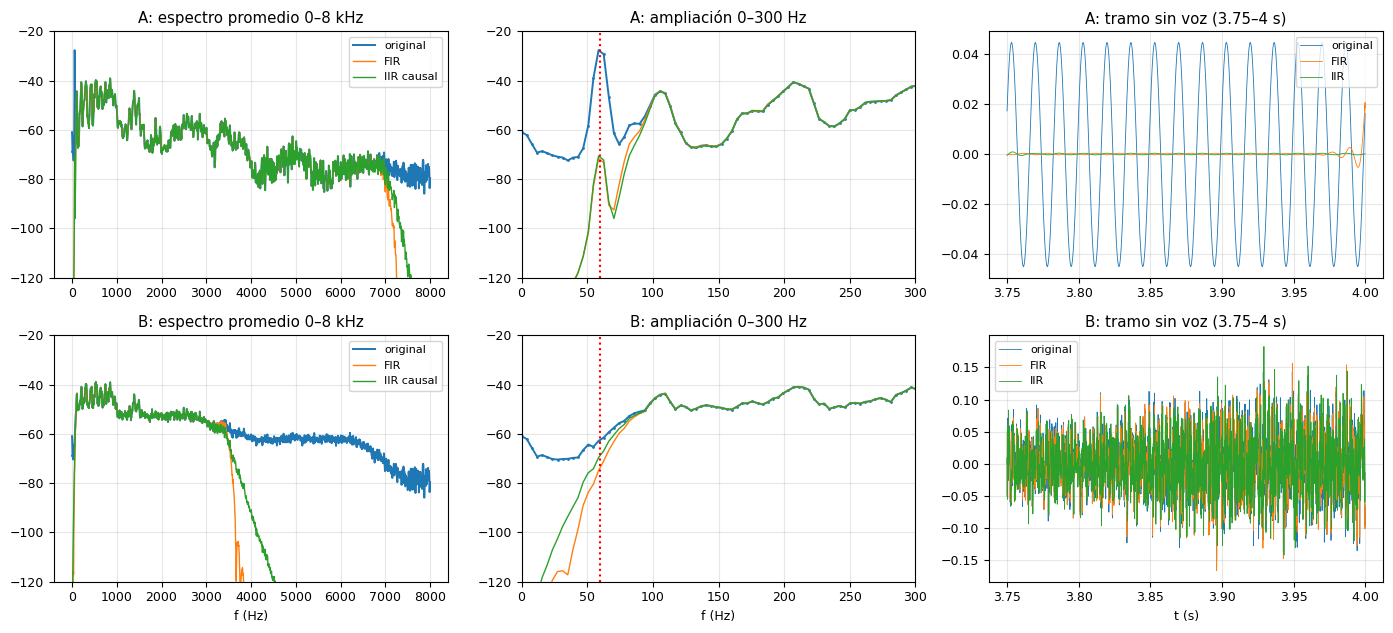

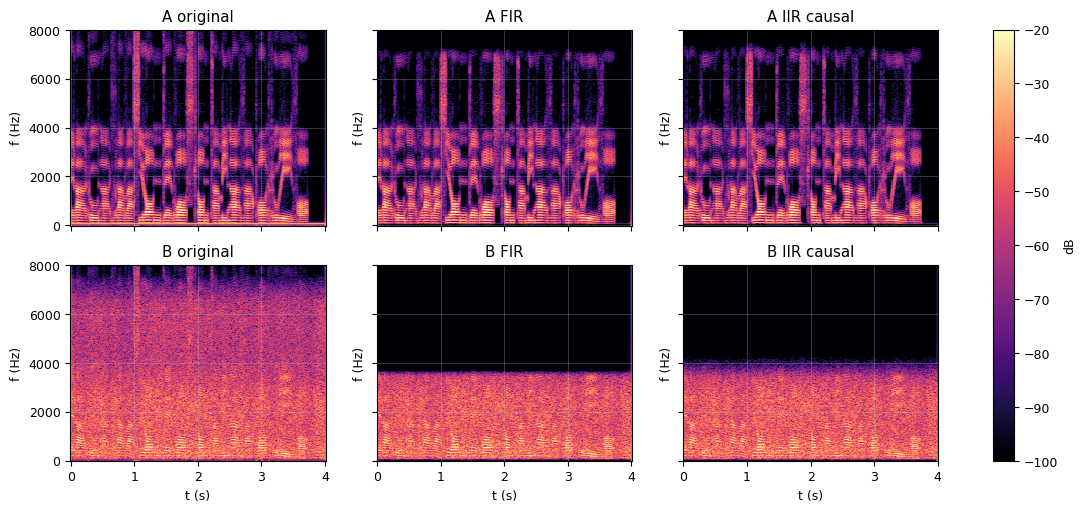

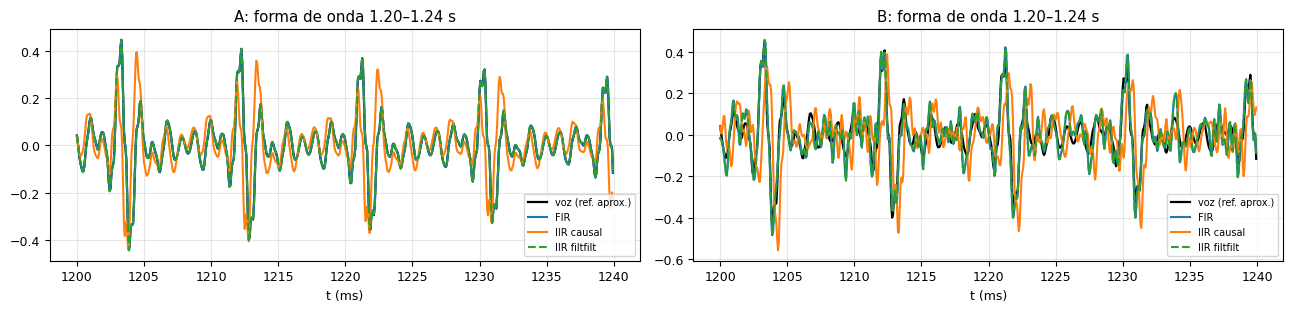

In [ ]:
# Evidencia antes/después: espectros promedio (Hann L = 4096) y espectrogramas
fig, ax = plt.subplots(2, 3, figsize=(14, 6.4))
for i, (k, x, yf, yi) in enumerate((('A', xA, yA_fir, yA_iir), ('B', xB, yB_fir, yB_iir))):
    for y, nom, lw in ((x, 'original', 1.4), (yf, 'FIR', 1), (yi, 'IIR causal', 1)):
        f, _, Sp, _ = espectro_segmentos(y, 4096)
        ax[i, 0].plot(f, dB(Sp), label=nom, lw=lw); ax[i, 1].plot(f, dB(Sp), label=nom, lw=lw, marker='.' if nom == 'original' else None, ms=2)
    ax[i, 0].set_title(f'{k}: espectro promedio 0–8 kHz'); ax[i, 0].set_ylim(-120, -20); ax[i, 0].legend(fontsize=8)
    ax[i, 1].set_xlim(0, 300); ax[i, 1].set_ylim(-120, -20); ax[i, 1].set_title(f'{k}: ampliación 0–300 Hz'); ax[i, 1].axvline(60, color='r', ls=':')
    sel = t >= 3.75
    ax[i, 2].plot(t[sel], x[sel], lw=.6, label='original'); ax[i, 2].plot(t[sel], yf[sel], lw=.6, label='FIR'); ax[i, 2].plot(t[sel], yi[sel], lw=.6, label='IIR')
    ax[i, 2].set_title(f'{k}: tramo sin voz (3.75–4 s)'); ax[i, 2].legend(fontsize=8)
for a in ax[1]: a.set_xlabel('f (Hz)')
ax[1, 2].set_xlabel('t (s)')
plt.tight_layout(); plt.savefig('figuras/antes_despues.png', dpi=150, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(14, 5.6), sharex=True, sharey=True)
for i, (k, x, yf, yi) in enumerate((('A', xA, yA_fir, yA_iir), ('B', xB, yB_fir, yB_iir))):
    for j, (y, nom) in enumerate(((x, 'original'), (yf, 'FIR'), (yi, 'IIR causal'))):
        im = espectrograma(ax[i, j], y, f'{k} {nom}')
for a in ax[1]: a.set_xlabel('t (s)')
fig.colorbar(im, ax=ax, label='dB'); plt.savefig('figuras/espectrogramas.png', dpi=150, bbox_inches='tight'); plt.show()

# Forma de onda de la voz: efecto de la fase (zoom en un tramo con voz)
sel = (t >= 1.20) & (t < 1.24)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
for a, k, yf, yi, yi0 in ((ax[0], 'A', yA_fir, yA_iir, yA_iir0), (ax[1], 'B', yB_fir, yB_iir, yB_iir0)):
    a.plot(1000*t[sel], v_ref[sel], 'k', lw=1.6, label='voz (ref. aprox.)'); a.plot(1000*t[sel], yf[sel], label='FIR')
    a.plot(1000*t[sel], yi[sel], label='IIR causal'); a.plot(1000*t[sel], yi0[sel], '--', label='IIR filtfilt')
    a.set_title(f'{k}: forma de onda 1.20–1.24 s'); a.set_xlabel('t (ms)'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig('figuras/fase_forma_onda.png', dpi=150, bbox_inches='tight'); plt.show()